# Priorización de alertas de Suricata mediante Isolation Forest

Parto de `eve.json`. Quiero comprobar si ordenar por anomalía deja alertas relevantes arriba y en qué se diferencia esa selección de la que obtengo por severidad y frecuencia. Después pruebo qué cambia al quitar los puertos y al filtrar tres firmas.

Para repetir el análisis, ajusto las rutas de la primera celda y ejecuto en orden. El PCAP, los registros EVE y los CSV de revisión son internos. Antes de publicar, reviso el código y limpio las salidas con datos de la captura.

## 1. Antes de empezar: entorno y rutas

Primero compruebo con qué Python estoy trabajando y si tengo a mano los archivos que necesito.

In [1]:
import sys
from pathlib import Path
import os
import json

import numpy as np
import pandas as pd
import sklearn
import matplotlib.pyplot as plt
from sklearn.ensemble import IsolationForest

project_path = Path.home() / "tfm"
pcap_path = project_path / "pcaps_originales" / "Captura_TFM.pcapng"
eve_path = project_path / "resultados" / "pcap_Captura_TFM" / "eve.json"
output_path = project_path / "resultados" / "pcap_Captura_TFM"

print("Python ejecutado desde:", sys.executable)
print("Versión de Python:", sys.version.split()[0])
print("Versión de NumPy:", np.__version__)
print("Versión de pandas:", pd.__version__)
print("Versión de scikit-learn:", sklearn.__version__)
print()

for nombre, ruta in [
    ("PCAP", pcap_path),
    ("EVE JSON", eve_path),
    ("Carpeta de resultados", output_path),
]:
    existe = ruta.exists()
    print(f"{nombre}: {ruta}")
    print("  Existe:", existe)
    if ruta.is_file():
        print(f"  Tamaño: {ruta.stat().st_size / (1024**2):.2f} MiB")
        print("  Lectura permitida:", os.access(ruta, os.R_OK))

Python ejecutado desde: /home/nemsis/tfm/.venv/bin/python
Versión de Python: 3.14.4
Versión de NumPy: 2.5.4
Versión de pandas: 3.1.0
Versión de scikit-learn: 1.9.1

PCAP: /home/nemsis/tfm/pcaps_originales/Captura_TFM.pcapng
  Existe: True
  Tamaño: 18330.51 MiB
  Lectura permitida: True
EVE JSON: /home/nemsis/tfm/resultados/pcap_Captura_TFM/eve.json
  Existe: True
  Tamaño: 200.04 MiB
  Lectura permitida: True
Carpeta de resultados: /home/nemsis/tfm/resultados/pcap_Captura_TFM
  Existe: True


## 2. De EVE JSON a la tabla de alertas

Leo el fichero línea a línea y me quedo con los eventos de tipo `alert`. El recuento inicial me sirve para ver qué ha entrado antes de preparar las variables.

In [2]:
from collections import Counter

eventos_por_tipo = Counter()
alertas_eve = []
lineas_leidas = 0
lineas_malformadas = 0

with eve_path.open("r", encoding="utf-8") as archivo:
    for linea in archivo:
        lineas_leidas += 1

        try:
            evento = json.loads(linea)
        except json.JSONDecodeError:
            lineas_malformadas += 1
            continue

        tipo = evento.get("event_type", "(sin event_type)")
        eventos_por_tipo[tipo] += 1

        if tipo == "alert":
            alertas_eve.append(evento)

df_alertas = pd.json_normalize(alertas_eve, sep=".")

print(f"Líneas leídas: {lineas_leidas:,}")
print(f"Líneas JSON malformadas: {lineas_malformadas:,}")
print(f"Alertas seleccionadas: {len(df_alertas):,}")
print(f"Dimensiones de df_alertas: {df_alertas.shape}")

print("\nRegistros EVE por tipo:")
for tipo, cantidad in eventos_por_tipo.most_common():
    print(f"{tipo}: {cantidad:,}")

print("\nColumnas disponibles en los registros de alerta:")
for columna in df_alertas.columns:
    print(columna)

campos_revisar = [
    "src_ip",
    "dest_ip",
    "src_port",
    "dest_port",
    "proto",
    "flow_id",
    "app_proto",
    "pcap_cnt",
    "alert.signature_id",
    "alert.signature",
    "alert.category",
    "alert.severity",
    "alert.action",
]

print("\nPresencia de campos en las alertas:")
for campo in campos_revisar:
    if campo not in df_alertas.columns:
        print(f"{campo}: campo no presente")
        continue

    valores = df_alertas[campo]
    presentes = valores.notna()

    if pd.api.types.is_object_dtype(valores) or pd.api.types.is_string_dtype(valores):
        presentes &= valores.astype("string").str.strip().ne("").fillna(False)

    cantidad = int(presentes.sum())
    porcentaje = cantidad / len(df_alertas) * 100 if len(df_alertas) else 0
    print(f"{campo}: {cantidad:,}/{len(df_alertas):,} ({porcentaje:.1f} %)")

print("\nNúmero de valores distintos en campos candidatos:")
for campo in [
    "proto",
    "app_proto",
    "src_port",
    "dest_port",
    "alert.category",
    "alert.signature_id",
]:
    if campo in df_alertas.columns:
        print(f"{campo}: {df_alertas[campo].nunique(dropna=True):,}")

Líneas leídas: 323,956
Líneas JSON malformadas: 0
Alertas seleccionadas: 65,600
Dimensiones de df_alertas: (65600, 104)

Registros EVE por tipo:
dns: 102,173
flow: 70,084
alert: 65,600
quic: 44,137
mdns: 22,118
tls: 11,829
fileinfo: 2,891
http: 2,474
smb: 1,544
ike: 346
anomaly: 267
ldap: 192
dcerpc: 164
dhcp: 67
krb5: 50
snmp: 8
ssh: 6
stats: 6

Columnas disponibles en los registros de alerta:
timestamp
flow_id
pcap_cnt
event_type
src_ip
src_port
dest_ip
dest_port
proto
ip_v
pkt_src
app_proto
direction
pcap_filename
alert.action
alert.gid
alert.signature_id
alert.rev
alert.signature
alert.category
alert.severity
flow.pkts_toserver
flow.pkts_toclient
flow.bytes_toserver
flow.bytes_toclient
flow.start
flow.src_ip
flow.dest_ip
flow.src_port
flow.dest_port
alert.metadata.confidence
alert.metadata.created_at
alert.metadata.signature_severity
alert.metadata.tag
alert.metadata.updated_at
tx_id
ts_progress
tc_progress
alert.source.ip
alert.source.port
alert.target.ip
alert.target.port
alert.m

### 2.1. Qué campos tengo y qué periodo cubren

Aquí miro cuántos registros traen cada campo, cuántos valores distintos aparecen y entre qué fechas están las alertas.

In [3]:
campos_candidatos = [
    "timestamp",
    "ip_v",
    "direction",
    "proto",
    "app_proto",
    "src_port",
    "dest_port",
    "flow.pkts_toserver",
    "flow.pkts_toclient",
    "flow.bytes_toserver",
    "flow.bytes_toclient",
    "flow.start",
    "alert.category",
    "alert.signature_id",
    "alert.severity",
    "alert.action",
    "flow.end",
    "flow.age",
    "flow.state",
    "flow.reason",
]

print("Disponibilidad y cardinalidad de campos:")
for campo in campos_candidatos:
    if campo not in df_alertas.columns:
        print(f"{campo}: no aparece en los registros de alerta")
        continue

    serie = df_alertas[campo]
    presentes = serie.notna()

    if pd.api.types.is_object_dtype(serie) or pd.api.types.is_string_dtype(serie):
        presentes &= serie.astype("string").str.strip().ne("").fillna(False)

    cantidad = int(presentes.sum())
    porcentaje = cantidad / len(df_alertas) * 100
    distintos = serie.nunique(dropna=True)

    print(
        f"{campo}: tipo={serie.dtype}, "
        f"presentes={cantidad:,}/{len(df_alertas):,} ({porcentaje:.1f} %), "
        f"valores distintos={distintos:,}"
    )

print("\nRango temporal de las alertas:")
marcas_tiempo = pd.to_datetime(
    df_alertas["timestamp"],
    utc=True,
    errors="coerce"
)
print("Marcas temporales interpretadas:", marcas_tiempo.notna().sum())
print("Marcas temporales no interpretadas:", marcas_tiempo.isna().sum())
print("Primera alerta:", marcas_tiempo.min())
print("Última alerta:", marcas_tiempo.max())

Disponibilidad y cardinalidad de campos:
timestamp: tipo=str, presentes=65,600/65,600 (100.0 %), valores distintos=42,740
ip_v: tipo=float64, presentes=62,797/65,600 (95.7 %), valores distintos=1
direction: tipo=str, presentes=62,787/65,600 (95.7 %), valores distintos=2
proto: tipo=str, presentes=62,797/65,600 (95.7 %), valores distintos=4
app_proto: tipo=str, presentes=43,825/65,600 (66.8 %), valores distintos=8
src_port: tipo=float64, presentes=62,787/65,600 (95.7 %), valores distintos=8,475
dest_port: tipo=float64, presentes=62,787/65,600 (95.7 %), valores distintos=3,505
flow.pkts_toserver: tipo=float64, presentes=62,787/65,600 (95.7 %), valores distintos=1,700
flow.pkts_toclient: tipo=float64, presentes=62,787/65,600 (95.7 %), valores distintos=550
flow.bytes_toserver: tipo=float64, presentes=62,787/65,600 (95.7 %), valores distintos=3,785
flow.bytes_toclient: tipo=float64, presentes=62,787/65,600 (95.7 %), valores distintos=1,371
flow.start: tipo=str, presentes=62,787/65,600 (95.

## 3. Qué le paso al modelo

Preparo las variables categóricas y numéricas y calculo cuánto tiempo llevaba abierto el flujo cuando saltó la alerta. Dejo aparte los campos que necesito para identificar u ordenar los registros.

In [4]:
caracteristicas_categoricas = [
    "proto",
    "app_proto",
    "direction",
    "alert.category",
]

caracteristicas_numericas = [
    "src_port",
    "dest_port",
    "flow.pkts_toserver",
    "flow.pkts_toclient",
    "flow.bytes_toserver",
    "flow.bytes_toclient",
]

# Se interpretan las marcas temporales con zona horaria
# para ordenarlas correctamente aunque estén expresadas en UTC.
timestamp_alerta = pd.to_datetime(
    df_alertas["timestamp"],
    utc=True,
    errors="coerce",
)

timestamp_inicio_flujo = pd.to_datetime(
    df_alertas["flow.start"],
    utc=True,
    errors="coerce",
)

# Tiempo transcurrido desde el inicio del flujo hasta la alerta.
tiempo_hasta_alerta = (
    timestamp_alerta - timestamp_inicio_flujo
).dt.total_seconds()

# Empiezo con cuatro categóricas y seis numéricas. La duración se añade al final.
X_raw = pd.DataFrame(index=df_alertas.index)

for campo in caracteristicas_categoricas:
    valores = df_alertas[campo].astype("string").str.strip()
    valores = valores.mask(valores.eq(""))
    X_raw[campo] = valores.astype(object).where(valores.notna(), np.nan)

for campo in caracteristicas_numericas:
    X_raw[campo] = pd.to_numeric(
        df_alertas[campo],
        errors="coerce",
    )

X_raw["flow_elapsed_seconds"] = tiempo_hasta_alerta

# Metadatos separados: se conservan para ordenación,
# identificación y evaluación, pero no son predictores.
columnas_metadatos = [
    "timestamp",
    "pcap_cnt",
    "flow_id",
    "alert.signature_id",
    "alert.signature",
    "alert.severity",
    "alert.category",
]

meta_alertas = df_alertas[columnas_metadatos].copy()
meta_alertas["timestamp_utc"] = timestamp_alerta

print("Dimensiones de X_raw:", X_raw.shape)
print("Dimensiones de meta_alertas:", meta_alertas.shape)

print("\nValores ausentes en características:")
for campo in X_raw.columns:
    ausentes = int(X_raw[campo].isna().sum())
    porcentaje = ausentes / len(X_raw) * 100
    print(f"{campo}: {ausentes:,} ({porcentaje:.2f} %)")

print("\nDuración del flujo hasta la alerta:")
duracion = X_raw["flow_elapsed_seconds"]
print("Valores disponibles:", int(duracion.notna().sum()))
print("Valores negativos:", int((duracion < 0).sum()))
print("Mínimo:", duracion.min())
print("Mediana:", duracion.median())
print("Percentil 95:", duracion.quantile(0.95))
print("Máximo:", duracion.max())

Dimensiones de X_raw: (65600, 11)
Dimensiones de meta_alertas: (65600, 8)

Valores ausentes en características:
proto: 2,803 (4.27 %)
app_proto: 21,775 (33.19 %)
direction: 2,813 (4.29 %)
alert.category: 0 (0.00 %)
src_port: 2,813 (4.29 %)
dest_port: 2,813 (4.29 %)
flow.pkts_toserver: 2,813 (4.29 %)
flow.pkts_toclient: 2,813 (4.29 %)
flow.bytes_toserver: 2,813 (4.29 %)
flow.bytes_toclient: 2,813 (4.29 %)
flow_elapsed_seconds: 2,813 (4.29 %)

Duración del flujo hasta la alerta:
Valores disponibles: 62787
Valores negativos: 0
Mínimo: 0.0
Mediana: 0.00123
Percentil 95: 805.840172
Máximo: 3088.381091


## 4. Dónde separo entrenamiento y evaluación

Hago el corte al 70 % de la duración de la captura. Ajusto el modelo con el primer tramo y dejo el siguiente para comprobar qué alertas coloca arriba.

In [5]:
# Inicio de captura que muestra capinfos:
# 4 de noviembre de 2026, 12:57:09.878295800, hora local de España.
# Se convierte a UTC, zona en la que queda normalizada la columna timestamp_utc.
inicio_captura_utc = pd.Timestamp(
    "2026-11-04T11:57:09.878295800+00:00"
)

duracion_captura_segundos = 3247.3893705
proporcion_entrenamiento = 0.70

corte_temporal_utc = inicio_captura_utc + pd.to_timedelta(
    duracion_captura_segundos * proporcion_entrenamiento,
    unit="s",
)

# Orden estable por marca temporal y, en caso de empate, por pcap_cnt.
meta_ordenada = meta_alertas.sort_values(
    ["timestamp_utc", "pcap_cnt"],
    kind="mergesort",
    na_position="last",
)

indices_entrenamiento = meta_ordenada.index[
    meta_ordenada["timestamp_utc"] < corte_temporal_utc
]

indices_evaluacion = meta_ordenada.index[
    meta_ordenada["timestamp_utc"] >= corte_temporal_utc
]

# Se crean los subconjuntos sin ajustar aún ningún imputador ni codificador.
X_entrenamiento_raw = X_raw.loc[indices_entrenamiento].copy()
X_evaluacion_raw = X_raw.loc[indices_evaluacion].copy()

meta_entrenamiento = meta_alertas.loc[indices_entrenamiento].copy()
meta_evaluacion = meta_alertas.loc[indices_evaluacion].copy()

print("Corte temporal, hora local de España:",
      corte_temporal_utc.tz_convert("Europe/Madrid"))
print()

print(f"Alertas en entrenamiento: {len(X_entrenamiento_raw):,} "
      f"({len(X_entrenamiento_raw) / len(X_raw) * 100:.2f} %)")
print(f"Alertas en evaluación: {len(X_evaluacion_raw):,} "
      f"({len(X_evaluacion_raw) / len(X_raw) * 100:.2f} %)")

print("\nIntervalo de entrenamiento, hora local:")
print(meta_entrenamiento["timestamp_utc"].min().tz_convert("Europe/Madrid"))
print(meta_entrenamiento["timestamp_utc"].max().tz_convert("Europe/Madrid"))

print("\nIntervalo de evaluación, hora local:")
print(meta_evaluacion["timestamp_utc"].min().tz_convert("Europe/Madrid"))
print(meta_evaluacion["timestamp_utc"].max().tz_convert("Europe/Madrid"))

print("\nFilas conservadas:")
print("Entrenamiento:", len(X_entrenamiento_raw))
print("Evaluación:", len(X_evaluacion_raw))
print("Total:", len(X_entrenamiento_raw) + len(X_evaluacion_raw))

Corte temporal, hora local de España: 2026-11-04 13:35:03.050855150+01:00

Alertas en entrenamiento: 40,279 (61.40 %)
Alertas en evaluación: 25,321 (38.60 %)

Intervalo de entrenamiento, hora local:
2026-11-04 12:57:10.466633+01:00
2026-11-04 13:35:02.904638+01:00

Intervalo de evaluación, hora local:
2026-11-04 13:35:03.062007+01:00
2026-11-04 13:51:17.114271+01:00

Filas conservadas:
Entrenamiento: 40279
Evaluación: 25321
Total: 65600


## 5. Cómo vienen los contadores y la duración

Antes de aplicar `log1p`, miro los valores del entrenamiento para ver si la transformación se puede aplicar.

In [6]:
campos_a_comprobar = [
    "flow.pkts_toserver",
    "flow.pkts_toclient",
    "flow.bytes_toserver",
    "flow.bytes_toclient",
    "flow_elapsed_seconds",
]

for campo in campos_a_comprobar:
    serie = pd.to_numeric(
        X_entrenamiento_raw[campo],
        errors="coerce",
    ).dropna()

    print(f"\n{campo}")
    print(f"  Valores disponibles: {len(serie):,}")
    print(f"  Valores iguales a cero: {(serie == 0).sum():,}")
    print(f"  Mínimo: {serie.min():.6g}")
    print(f"  Mediana: {serie.median():.6g}")
    print(f"  Percentil 95: {serie.quantile(0.95):.6g}")
    print(f"  Percentil 99: {serie.quantile(0.99):.6g}")
    print(f"  Máximo: {serie.max():.6g}")

    if (serie < 0).any():
        print("  ATENCIÓN: hay valores negativos; no aplicar log1p todavía.")
    else:
        serie_log = np.log1p(serie)
        print("  Después de log1p:")
        print(f"    Mediana: {serie_log.median():.6g}")
        print(f"    Percentil 95: {serie_log.quantile(0.95):.6g}")
        print(f"    Percentil 99: {serie_log.quantile(0.99):.6g}")
        print(f"    Máximo: {serie_log.max():.6g}")


flow.pkts_toserver
  Valores disponibles: 38,373
  Valores iguales a cero: 0
  Mínimo: 1
  Mediana: 5
  Percentil 95: 886
  Percentil 99: 1850.28
  Máximo: 36995
  Después de log1p:
    Mediana: 1.79176
    Percentil 95: 6.78784
    Percentil 99: 7.52363
    Máximo: 10.5186

flow.pkts_toclient
  Valores disponibles: 38,373
  Valores iguales a cero: 16,483
  Mínimo: 0
  Mediana: 3
  Percentil 95: 20
  Percentil 99: 153
  Máximo: 134591
  Después de log1p:
    Mediana: 1.38629
    Percentil 95: 3.04452
    Percentil 99: 5.03695
    Máximo: 11.81

flow.bytes_toserver
  Valores disponibles: 38,373
  Valores iguales a cero: 0
  Mínimo: 60
  Mediana: 324
  Percentil 95: 69511
  Percentil 99: 141989
  Máximo: 1.17125e+07
  Después de log1p:
    Mediana: 5.78383
    Percentil 95: 11.1493
    Percentil 99: 11.8635
    Máximo: 16.2762

flow.bytes_toclient
  Valores disponibles: 38,373
  Valores iguales a cero: 16,483
  Mínimo: 0
  Mediana: 264
  Percentil 95: 5368
  Percentil 99: 12156.7
  Máxi

## 6. Preparación de los datos para el modelo

Codifico las categorías con one-hot. Aplico `log1p` a los contadores y la duración, y relleno los valores ausentes de esas variables con la mediana calculada en entrenamiento. En la primera prueba dejo los puertos como números. Más adelante repito el ajuste sin ellos.

Guardo la firma, la severidad, las IP, la hora y el número de paquete para identificar y ordenar las alertas. Esos campos quedan fuera de la entrada del modelo.

In [7]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder
from scipy.sparse import issparse

caracteristicas_categoricas = [
    "proto",
    "app_proto",
    "direction",
    "alert.category",
]

caracteristicas_puertos = [
    "src_port",
    "dest_port",
]

caracteristicas_logaritmicas = [
    "flow.pkts_toserver",
    "flow.pkts_toclient",
    "flow.bytes_toserver",
    "flow.bytes_toclient",
    "flow_elapsed_seconds",
]

preparador_categoricas = Pipeline([
    (
        "imputar_ausentes",
        SimpleImputer(
            strategy="constant",
            fill_value="__NO_DISPONIBLE__",
        ),
    ),
    (
        "codificar",
        OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=True,
            dtype=np.float32,
        ),
    ),
])

preparador_puertos = Pipeline([
    ("imputar_ausentes", SimpleImputer(strategy="median")),
])

preparador_logaritmico = Pipeline([
    (
        "log1p",
        FunctionTransformer(
            np.log1p,
            feature_names_out="one-to-one",
            validate=False,
        ),
    ),
    ("imputar_ausentes", SimpleImputer(strategy="median")),
])

preprocesador = ColumnTransformer(
    transformers=[
        (
            "categoricas",
            preparador_categoricas,
            caracteristicas_categoricas,
        ),
        (
            "puertos",
            preparador_puertos,
            caracteristicas_puertos,
        ),
        (
            "contadores_y_tiempo",
            preparador_logaritmico,
            caracteristicas_logaritmicas,
        ),
    ],
    remainder="drop",
    verbose_feature_names_out=False,
)

# Aquí ajusto categorías y medianas. Evaluación recibe la transformación ya ajustada.
X_entrenamiento = preprocesador.fit_transform(X_entrenamiento_raw)

# Mismas reglas para el tramo posterior.
X_evaluacion = preprocesador.transform(X_evaluacion_raw)

def valores_finitos(matriz):
    if issparse(matriz):
        return bool(np.isfinite(matriz.data).all())
    return bool(np.isfinite(matriz).all())

print("Matriz de entrenamiento:", X_entrenamiento.shape)
print("Matriz de evaluación:", X_evaluacion.shape)
print("Formato de la matriz:", type(X_entrenamiento).__name__)
print("Valores finitos en entrenamiento:", valores_finitos(X_entrenamiento))
print("Valores finitos en evaluación:", valores_finitos(X_evaluacion))
print("Número de características tras la codificación:",
      len(preprocesador.get_feature_names_out()))

Matriz de entrenamiento: (40279, 29)
Matriz de evaluación: (25321, 29)
Formato de la matriz: ndarray
Valores finitos en entrenamiento: True
Valores finitos en evaluación: True
Número de características tras la codificación: 29


## 7. Entreno Isolation Forest y ordeno las alertas

La idea es que una observación poco habitual suele quedar aislada en menos cortes aleatorios. La puntuación original se expresa como `s(x, ψ) = 2^(-E[h(x)] / c(ψ))`. Aquí `E[h(x)]` es la longitud media del camino y `c(ψ)` la normalización para el tamaño de muestra por árbol.

Uso 200 árboles, semilla 42 y `max_samples="auto"` (256 observaciones por árbol en esta ejecución). Invierto el signo de `score_samples` para ordenar primero lo más anómalo. El top 20 sale de ese orden. La puntuación indica rareza y la relevancia operativa se comprueba en la revisión experta.

In [8]:
from sklearn.ensemble import IsolationForest

modelo_if = IsolationForest(
    n_estimators=200,
    max_samples="auto",
    contamination="auto",
    max_features=1.0,
    bootstrap=False,
    random_state=42,
    n_jobs=-1,
)

# Ajuste solo con el tramo inicial.
modelo_if.fit(X_entrenamiento)

# En score_samples, un valor menor indica mayor anomalía.
# Le doy la vuelta al signo: así, cuanto más alto, más raro.
puntuacion_anomalia_if = -modelo_if.score_samples(X_evaluacion)

resultados_if = meta_evaluacion.copy()
resultados_if["if_anomaly_score"] = puntuacion_anomalia_if

# Orden descendente por anomalía.
# Los empates se resuelven primero por hora y luego por número de paquete.
ranking_if = resultados_if.sort_values(
    ["if_anomaly_score", "timestamp_utc", "pcap_cnt"],
    ascending=[False, True, True],
    kind="mergesort",
    na_position="last",
).copy()

print("Modelo entrenado:", type(modelo_if).__name__)
print("Alertas usadas para entrenar:", X_entrenamiento.shape[0])
print("Alertas puntuadas:", len(puntuacion_anomalia_if))
print("Características de entrada:", X_entrenamiento.shape[1])
print("Muestras utilizadas por árbol:", modelo_if.max_samples_)
print("Puntuaciones finitas:", np.isfinite(puntuacion_anomalia_if).all())
print("Alertas en el ranking:", len(ranking_if))

print("\nParámetros principales:")
for parametro in [
    "n_estimators",
    "max_samples",
    "contamination",
    "max_features",
    "bootstrap",
    "random_state",
    "n_jobs",
]:
    print(f"{parametro}: {modelo_if.get_params()[parametro]}")

print("\nDistribución de la puntuación de anomalía:")
print(pd.Series(puntuacion_anomalia_if).describe(
    percentiles=[0.25, 0.50, 0.75, 0.95]
))

Modelo entrenado: IsolationForest
Alertas usadas para entrenar: 40279
Alertas puntuadas: 25321
Características de entrada: 29
Muestras utilizadas por árbol: 256
Puntuaciones finitas: True
Alertas en el ranking: 25321

Parámetros principales:
n_estimators: 200
max_samples: auto
contamination: auto
max_features: 1.0
bootstrap: False
random_state: 42
n_jobs: -1

Distribución de la puntuación de anomalía:
count    25321.000000
mean         0.472661
std          0.062851
min          0.364973
25%          0.425149
50%          0.465791
75%          0.503518
95%          0.593612
max          0.710624
dtype: float64


### 7.1. Cómo se reparten las puntuaciones

En el histograma marco la puntuación del puesto 20. Luego miro en qué momentos aparecen las alertas seleccionadas. Si dos alertas empatan, manda la hora y después `pcap_cnt`.

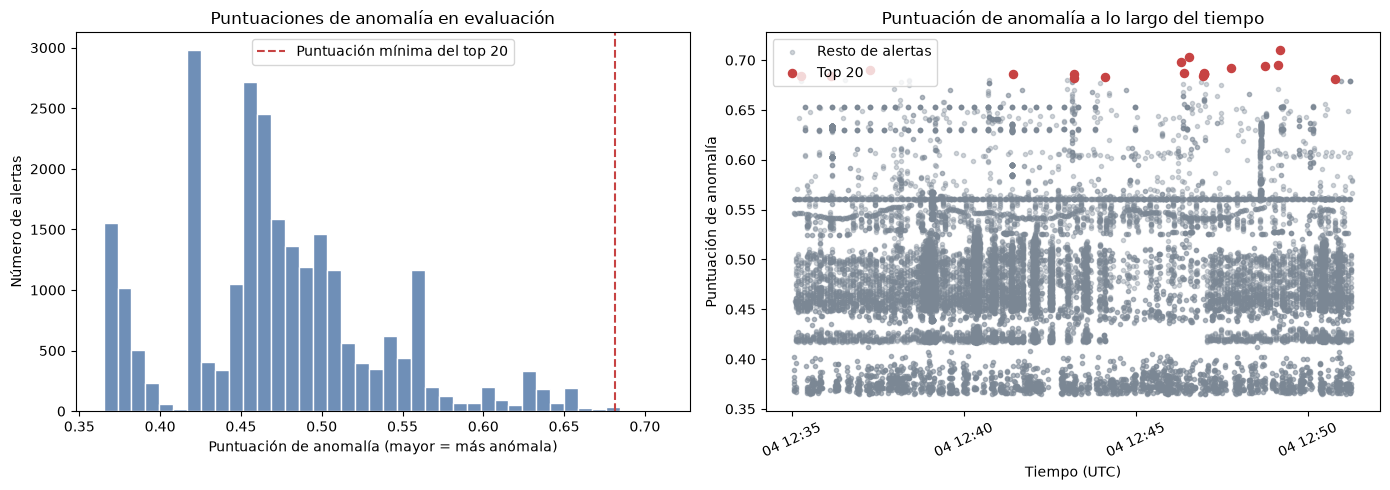

In [9]:
# Umbral de puntuación correspondiente a la posición 20 del ranking.
top20_if = ranking_if.head(20).copy()
umbral_top20_if = top20_if["if_anomaly_score"].min()

fig, ejes = plt.subplots(1, 2, figsize=(14, 5))

# Distribución de puntuaciones.
ejes[0].hist(
    ranking_if["if_anomaly_score"],
    bins=40,
    color="#6f8fb7",
    edgecolor="white",
)
ejes[0].axvline(
    umbral_top20_if,
    color="#c74343",
    linestyle="--",
    label="Puntuación mínima del top 20",
)
ejes[0].set_title("Puntuaciones de anomalía en evaluación")
ejes[0].set_xlabel("Puntuación de anomalía (mayor = más anómala)")
ejes[0].set_ylabel("Número de alertas")
ejes[0].legend()

# Evolución cronológica de las puntuaciones y alertas top 20.
evaluacion_score_tiempo = ranking_if.sort_values("timestamp_utc")
ejes[1].scatter(
    evaluacion_score_tiempo["timestamp_utc"],
    evaluacion_score_tiempo["if_anomaly_score"],
    s=9,
    alpha=0.35,
    color="#7b8794",
    label="Resto de alertas",
)
ejes[1].scatter(
    top20_if["timestamp_utc"],
    top20_if["if_anomaly_score"],
    s=34,
    color="#c74343",
    label="Top 20",
)
ejes[1].set_title("Puntuación de anomalía a lo largo del tiempo")
ejes[1].set_xlabel("Tiempo (UTC)")
ejes[1].set_ylabel("Puntuación de anomalía")
ejes[1].tick_params(axis="x", rotation=25)
ejes[1].legend()

fig.tight_layout()
plt.show()


### 7.2. Qué firmas se repiten arriba

Cuento las firmas del top 20 para ver si el ranking se concentra en unas pocas. Este recuento describe la selección.

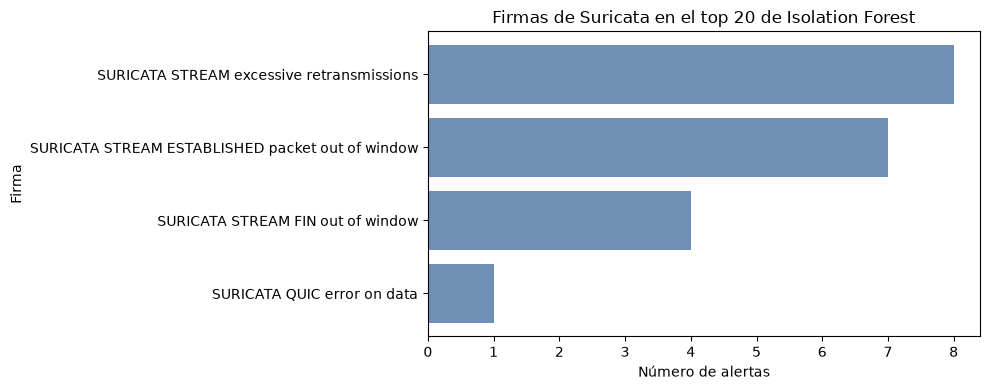

In [10]:
conteo_firmas_top20 = (
    top20_if["alert.signature"]
    .value_counts()
    .sort_values(ascending=True)
)

fig, ax = plt.subplots(figsize=(10, max(4, 0.38 * len(conteo_firmas_top20))))
ax.barh(conteo_firmas_top20.index, conteo_firmas_top20.values, color="#6f8fb7")
ax.set_title("Firmas de Suricata en el top 20 de Isolation Forest")
ax.set_xlabel("Número de alertas")
ax.set_ylabel("Firma")
fig.tight_layout()
plt.show()


### 7.3. En qué se parece el top 20

Comparo el top 20 con el resto. Para los contadores y la duración uso la distancia entre medianas en unidades de rango intercuartílico tras `log1p`. Para las categorías y los puertos miro qué valores se repiten. Esto me describe el grupo y deja abierta la contribución de cada variable a la puntuación.

,Variable,Mediana top 20 (log1p),Mediana resto (log1p),Diferencia en IQR del resto
0,flow.pkts_toserver,6.937,1.946,3.897
1,flow.pkts_toclient,7.791,1.609,5.244
2,flow.bytes_toserver,11.791,5.953,3.961
3,flow.bytes_toclient,14.911,5.580,5.895
4,flow_elapsed_seconds,4.730,0.001,914.318


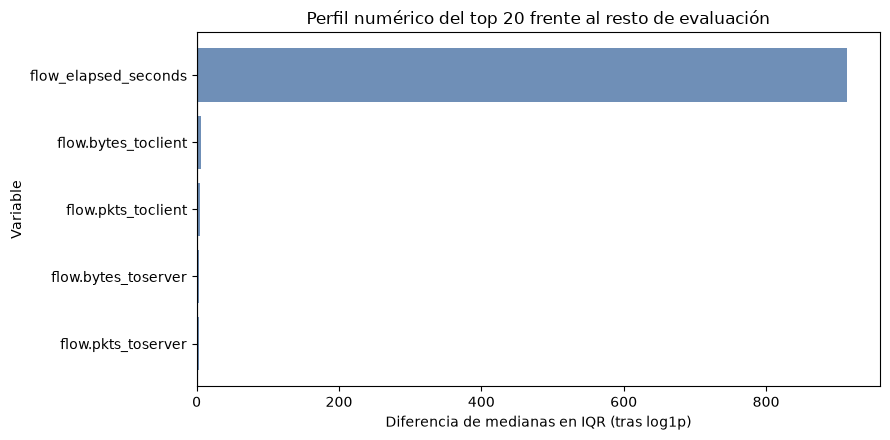

,Variable,Categoría más frecuente en top 20,Proporción top 20,Proporción resto evaluación
0,proto,TCP,0.95,0.738
1,app_proto,tls,0.95,0.009
2,direction,to_client,1.00,0.395
3,alert.category,Generic Protocol Command Decode,1.00,0.921


Puertos más frecuentes en el top 20: src_port


,Campo,Puerto,N.º top 20,Proporción top 20,Proporción resto evaluación
0,src_port,443.0,20,1.0,0.007


Puertos más frecuentes en el top 20: dest_port


,Campo,Puerto,N.º top 20,Proporción top 20,Proporción resto evaluación
0,dest_port,53226.0,6,0.30,0.0
1,dest_port,36406.0,2,0.10,0.0
2,dest_port,63389.0,1,0.05,0.0
3,dest_port,38752.0,1,0.05,0.0
4,dest_port,51931.0,1,0.05,0.0


In [11]:
indices_top20_principal = ranking_if.head(20).index
indices_resto_evaluacion = ranking_if.iloc[20:].index

variables_numericas_perfil = [
    "flow.pkts_toserver",
    "flow.pkts_toclient",
    "flow.bytes_toserver",
    "flow.bytes_toclient",
    "flow_elapsed_seconds",
]

filas_perfil_numerico = []
for variable in variables_numericas_perfil:
    valores_top20 = pd.to_numeric(
        X_raw.loc[indices_top20_principal, variable], errors="coerce"
    ).dropna()
    valores_resto = pd.to_numeric(
        X_raw.loc[indices_resto_evaluacion, variable], errors="coerce"
    ).dropna()

    top20_log = np.log1p(valores_top20)
    resto_log = np.log1p(valores_resto)
    q25, q75 = resto_log.quantile([0.25, 0.75])
    iqr_resto = q75 - q25
    diferencia_iqr = (
        (top20_log.median() - resto_log.median()) / iqr_resto
        if iqr_resto > 0 else np.nan
    )

    filas_perfil_numerico.append({
        "Variable": variable,
        "Mediana top 20 (log1p)": top20_log.median(),
        "Mediana resto (log1p)": resto_log.median(),
        "Diferencia en IQR del resto": diferencia_iqr,
    })

perfil_numerico_top20 = pd.DataFrame(filas_perfil_numerico)
display(perfil_numerico_top20.round(3))

fig, ax = plt.subplots(figsize=(9, 4.5))
perfil_grafico = perfil_numerico_top20.dropna(
    subset=["Diferencia en IQR del resto"]
).sort_values("Diferencia en IQR del resto")
ax.barh(
    perfil_grafico["Variable"],
    perfil_grafico["Diferencia en IQR del resto"],
    color="#6f8fb7",
)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_title("Perfil numérico del top 20 frente al resto de evaluación")
ax.set_xlabel("Diferencia de medianas en IQR (tras log1p)")
ax.set_ylabel("Variable")
fig.tight_layout()
plt.show()

variables_categoricas_perfil = [
    "proto", "app_proto", "direction", "alert.category"
]
filas_perfil_categorico = []
for variable in variables_categoricas_perfil:
    valores_top20 = (
        X_raw.loc[indices_top20_principal, variable]
        .astype("string").fillna("__NO_DISPONIBLE__")
    )
    valores_resto = (
        X_raw.loc[indices_resto_evaluacion, variable]
        .astype("string").fillna("__NO_DISPONIBLE__")
    )
    categoria = valores_top20.value_counts().index[0]
    filas_perfil_categorico.append({
        "Variable": variable,
        "Categoría más frecuente en top 20": categoria,
        "Proporción top 20": (valores_top20 == categoria).mean(),
        "Proporción resto evaluación": (valores_resto == categoria).mean(),
    })

display(pd.DataFrame(filas_perfil_categorico).round(3))

# Los puertos se presentan como etiquetas/categorías para evitar interpretarlos como magnitudes.
for variable in ["src_port", "dest_port"]:
    puertos_top20 = df_alertas.loc[indices_top20_principal, variable]
    puertos_resto = df_alertas.loc[indices_resto_evaluacion, variable]
    valores_frecuentes = puertos_top20.value_counts(dropna=True).head(5).index
    filas = []
    for puerto in valores_frecuentes:
        filas.append({
            "Campo": variable,
            "Puerto": puerto,
            "N.º top 20": int((puertos_top20 == puerto).sum()),
            "Proporción top 20": float((puertos_top20 == puerto).mean()),
            "Proporción resto evaluación": float((puertos_resto == puerto).mean()),
        })
    print(f"Puertos más frecuentes en el top 20: {variable}")
    display(pd.DataFrame(filas).round(3))


### 7.4. Qué cambia si quito los puertos

Los puertos identifican servicios o extremos de una conexión. Repito el ajuste con las mismas fechas y parámetros, quitando origen y destino, y comparo qué alertas llegan arriba y cuántas firmas y flujos representan.

,Modelo,Firmas distintas en top 20,Flujos distintos en top 20
0,Con puertos numéricos,4,14
1,Sin puertos,4,9


Alertas compartidas entre los dos top 20: 15 de 20


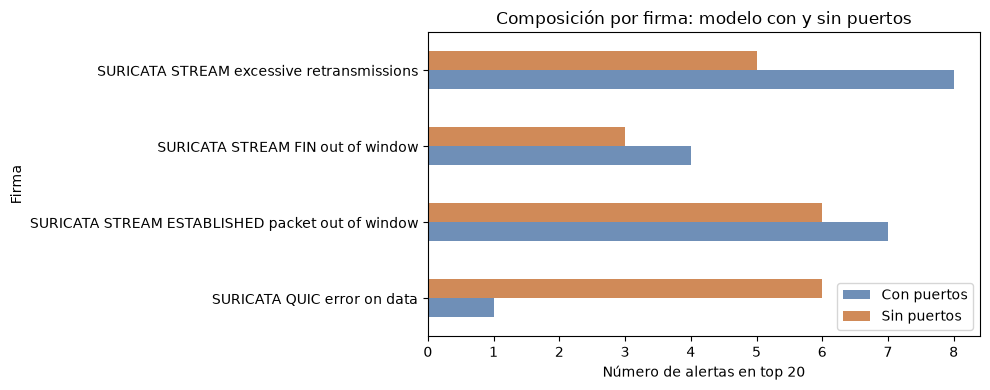

In [12]:
from sklearn.base import clone
from sklearn.compose import ColumnTransformer

preprocesador_sin_puertos = ColumnTransformer(
    transformers=[
        (
            "categoricas",
            clone(preparador_categoricas),
            caracteristicas_categoricas,
        ),
        (
            "contadores_y_tiempo",
            clone(preparador_logaritmico),
            caracteristicas_logaritmicas,
        ),
    ],
    remainder="drop",
    verbose_feature_names_out=False,
)

X_entrenamiento_sin_puertos = preprocesador_sin_puertos.fit_transform(
    X_entrenamiento_raw
)
X_evaluacion_sin_puertos = preprocesador_sin_puertos.transform(
    X_evaluacion_raw
)

modelo_if_sin_puertos = IsolationForest(
    n_estimators=200,
    max_samples="auto",
    contamination="auto",
    max_features=1.0,
    bootstrap=False,
    random_state=42,
    n_jobs=-1,
)
modelo_if_sin_puertos.fit(X_entrenamiento_sin_puertos)

resultados_if_sin_puertos = meta_evaluacion.copy()
resultados_if_sin_puertos["if_anomaly_score"] = -modelo_if_sin_puertos.score_samples(
    X_evaluacion_sin_puertos
)

ranking_if_sin_puertos = resultados_if_sin_puertos.sort_values(
    ["if_anomaly_score", "timestamp_utc", "pcap_cnt"],
    ascending=[False, True, True],
    kind="mergesort",
    na_position="last",
).copy()

top20_if_sin_puertos = ranking_if_sin_puertos.head(20).copy()
indices_top20_con_puertos = set(ranking_if.head(20).index)
indices_top20_sin_puertos = set(top20_if_sin_puertos.index)

resumen_puertos = pd.DataFrame([
    {
        "Modelo": "Con puertos numéricos",
        "Firmas distintas en top 20": ranking_if.head(20)["alert.signature_id"].nunique(),
        "Flujos distintos en top 20": df_alertas.loc[ranking_if.head(20).index, "flow_id"].nunique(dropna=True),
    },
    {
        "Modelo": "Sin puertos",
        "Firmas distintas en top 20": top20_if_sin_puertos["alert.signature_id"].nunique(),
        "Flujos distintos en top 20": df_alertas.loc[top20_if_sin_puertos.index, "flow_id"].nunique(dropna=True),
    },
])

display(resumen_puertos)
print("Alertas compartidas entre los dos top 20:",
      len(indices_top20_con_puertos & indices_top20_sin_puertos), "de 20")

# Compara la composición por firma, sin mostrar registros individuales.
firmas_con = ranking_if.head(20)["alert.signature"].value_counts()
firmas_sin = top20_if_sin_puertos["alert.signature"].value_counts()
comparacion_firmas_puertos = pd.concat(
    [firmas_con.rename("Con puertos"), firmas_sin.rename("Sin puertos")],
    axis=1,
).fillna(0).sort_index()

ax = comparacion_firmas_puertos.plot(
    kind="barh",
    figsize=(10, max(4, 0.35 * len(comparacion_firmas_puertos))),
    color=["#6f8fb7", "#d08a58"],
)
ax.set_title("Composición por firma: modelo con y sin puertos")
ax.set_xlabel("Número de alertas en top 20")
ax.set_ylabel("Firma")
plt.tight_layout()
plt.show()


Me interesa separar dos preguntas: si cambia qué alertas llegan arriba y si cambia su precisión. La primera la puedo mirar comparando listas. Para la segunda necesito las etiquetas expertas.

## 8. Referencia por severidad de Suricata

Ordeno por severidad. Dentro del mismo nivel utilizo la hora y, si sigue el empate, el número de paquete.

In [13]:
# Se crea el ranking de referencia usando solo el tramo de evaluación.
ranking_severidad = meta_evaluacion.copy()

ranking_severidad["severity_num"] = pd.to_numeric(
    ranking_severidad["alert.severity"],
    errors="coerce",
)

# Orden:
# 1) menor valor de severidad primero;
# 2) marca temporal más antigua primero;
# 3) pcap_cnt como desempate adicional.
ranking_severidad = ranking_severidad.sort_values(
    ["severity_num", "timestamp_utc", "pcap_cnt"],
    ascending=[True, True, True],
    kind="mergesort",
    na_position="last",
).copy()

ranking_severidad["rank_suricata"] = range(
    1,
    len(ranking_severidad) + 1,
)

top20_severidad = ranking_severidad.head(20).copy()

print("Alertas en el ranking:", len(ranking_severidad))
print("Severidades ausentes:",
      ranking_severidad["severity_num"].isna().sum())
print("Valores de severidad encontrados:",
      sorted(ranking_severidad["severity_num"].dropna().unique()))

print("\nDistribución de severidad en evaluación:")
print(
    ranking_severidad["severity_num"]
    .value_counts()
    .sort_index()
    .to_string()
)

print("\nDistribución de severidad en las primeras 20 posiciones:")
print(
    top20_severidad["severity_num"]
    .value_counts()
    .sort_index()
    .to_string()
)

print("\nComprobaciones:")
print(
    "El ranking mantiene severidad ascendente:",
    ranking_severidad["severity_num"].is_monotonic_increasing,
)
print("Alertas en top 20:", len(top20_severidad))
print(
    "Marcas temporales interpretadas:",
    ranking_severidad["timestamp_utc"].notna().sum(),
)

Alertas en el ranking: 25321
Severidades ausentes: 0
Valores de severidad encontrados: [np.int64(1), np.int64(2), np.int64(3)]

Distribución de severidad en evaluación:
severity_num
1        1
2        7
3    25313

Distribución de severidad en las primeras 20 posiciones:
severity_num
1     1
2     7
3    12

Comprobaciones:
El ranking mantiene severidad ascendente: True
Alertas en top 20: 20
Marcas temporales interpretadas: 25321


## 9. Referencia por frecuencia histórica

Pongo primero las firmas con menos apariciones previas. Para cada paquete consulto el historial disponible hasta ese momento y lo actualizo después.

In [14]:
from collections import Counter

# Se ordena el conjunto de evaluación para recorrerlo cronológicamente.
evaluacion_ordenada = meta_evaluacion.sort_values(
    ["timestamp_utc", "pcap_cnt"],
    ascending=[True, True],
    kind="mergesort",
    na_position="last",
).copy()

# Historial inicial: todas las alertas del tramo de entrenamiento.
historico_firmas = Counter(
    meta_entrenamiento["alert.signature_id"].astype(int).tolist()
)

frecuencias_previas = {}

# Agrupar por marca temporal y número de paquete permite dar
# el mismo recuento previo a las alertas del mismo paquete.
for _, grupo in evaluacion_ordenada.groupby(
    ["timestamp_utc", "pcap_cnt"],
    sort=False,
    dropna=False,
):
    firmas_grupo = grupo["alert.signature_id"].astype(int).tolist()

    # ¿Cuántas veces había visto esta firma antes de este paquete?
    for indice, firma_id in grupo["alert.signature_id"].items():
        frecuencias_previas[indice] = historico_firmas[int(firma_id)]

    # Ahora sí: incorporo las alertas de este paquete al historial.
    historico_firmas.update(firmas_grupo)

serie_frecuencia_previa = pd.Series(
    frecuencias_previas,
    name="frecuencia_previa",
    dtype="int64",
)

resultados_frecuencia = evaluacion_ordenada.join(
    serie_frecuencia_previa
)

# Frecuencia más baja primero; los empates se resuelven
# cronológicamente y luego por pcap_cnt.
ranking_frecuencia = resultados_frecuencia.sort_values(
    ["frecuencia_previa", "timestamp_utc", "pcap_cnt"],
    ascending=[True, True, True],
    kind="mergesort",
    na_position="last",
).copy()

ranking_frecuencia["rank_frecuencia"] = range(
    1,
    len(ranking_frecuencia) + 1,
)

top20_frecuencia = ranking_frecuencia.head(20).copy()

print("Alertas en el ranking:", len(ranking_frecuencia))
print(
    "Identificadores de firma ausentes:",
    ranking_frecuencia["alert.signature_id"].isna().sum(),
)
print(
    "Firmas distintas en evaluación:",
    ranking_frecuencia["alert.signature_id"].nunique(),
)
print(
    "Alertas cuya firma no aparece previamente:",
    int((ranking_frecuencia["frecuencia_previa"] == 0).sum()),
)

print("\nDistribución de la frecuencia previa:")
print(
    ranking_frecuencia["frecuencia_previa"]
    .describe(percentiles=[0.25, 0.50, 0.75, 0.95])
)

print("\nComprobaciones:")
print(
    "Frecuencia no decreciente en el ranking:",
    ranking_frecuencia["frecuencia_previa"].is_monotonic_increasing,
)
print("Alertas en las primeras 20 posiciones:", len(top20_frecuencia))
print(
    "Alertas del top 20 con frecuencia previa cero:",
    int((top20_frecuencia["frecuencia_previa"] == 0).sum()),
)
print(
    "Frecuencia previa mínima y máxima del top 20:",
    int(top20_frecuencia["frecuencia_previa"].min()),
    int(top20_frecuencia["frecuencia_previa"].max()),
)

Alertas en el ranking: 25321
Identificadores de firma ausentes: 0
Firmas distintas en evaluación: 63
Alertas cuya firma no aparece previamente: 10

Distribución de la frecuencia previa:
count    25321.000000
mean      4538.491252
std       3497.165438
min          0.000000
25%       1979.000000
50%       3195.000000
75%       6090.000000
95%      11540.000000
max      12420.000000
Name: frecuencia_previa, dtype: float64

Comprobaciones:
Frecuencia no decreciente en el ranking: True
Alertas en las primeras 20 posiciones: 20
Alertas del top 20 con frecuencia previa cero: 10
Frecuencia previa mínima y máxima del top 20: 0 2


## 10. Qué alertas entran en la revisión

Tomo las 20 primeras de cada ranking. Si una alerta sale varias veces, la incluyo una sola vez en la revisión y guardo los puestos que ocupa en cada lista.

In [15]:
k = 20

rankings = {
    "Isolation Forest (con puertos)": ranking_if,
    "Isolation Forest (sin puertos)": ranking_if_sin_puertos,
    "Severidad Suricata": ranking_severidad,
    "Frecuencia histórica": ranking_frecuencia,
}

indices_por_metodo = {}
filas_correspondencia = []

for nombre_metodo, ranking in rankings.items():
    top = ranking.head(k)
    indices_por_metodo[nombre_metodo] = set(top.index)

    for posicion, indice_alerta in enumerate(top.index, start=1):
        filas_correspondencia.append({
            "indice_alerta": indice_alerta,
            "metodo": nombre_metodo,
            "posicion": posicion,
        })

correspondencia_metodos = pd.DataFrame(filas_correspondencia)
indices_union = set().union(*indices_por_metodo.values())

print("Alertas del top 20 sin puertos incluidas en el conjunto de revisión:",
      len(indices_top20_sin_puertos & indices_union), "de 20")

print(f"k por método: {k}")

print("\nAlertas únicas por ranking:")
for nombre, indices in indices_por_metodo.items():
    print(f"{nombre}: {len(indices)}")

print(f"\nAlertas distintas en la unión: {len(indices_union)}")

print("\nCoincidencias entre pares:")
nombres = list(indices_por_metodo)
for i in range(len(nombres)):
    for j in range(i + 1, len(nombres)):
        nombre_a, nombre_b = nombres[i], nombres[j]
        comunes = indices_por_metodo[nombre_a] & indices_por_metodo[nombre_b]
        print(f"{nombre_a} / {nombre_b}: {len(comunes)}")

comunes_cuatro = set.intersection(*indices_por_metodo.values())
print(f"\nAlertas presentes en los cuatro rankings: {len(comunes_cuatro)}")

print("\nAlertas exclusivas de cada ranking:")
for nombre, indices in indices_por_metodo.items():
    otros = set().union(*[
        conjunto
        for otro_nombre, conjunto in indices_por_metodo.items()
        if otro_nombre != nombre
    ])
    print(f"{nombre}: {len(indices - otros)}")

Alertas del top 20 sin puertos incluidas en el conjunto de revisión: 20 de 20
k por método: 20

Alertas únicas por ranking:
Isolation Forest (con puertos): 20
Isolation Forest (sin puertos): 20
Severidad Suricata: 20
Frecuencia histórica: 20

Alertas distintas en la unión: 64

Coincidencias entre pares:
Isolation Forest (con puertos) / Isolation Forest (sin puertos): 15
Isolation Forest (con puertos) / Severidad Suricata: 0
Isolation Forest (con puertos) / Frecuencia histórica: 0
Isolation Forest (sin puertos) / Severidad Suricata: 0
Isolation Forest (sin puertos) / Frecuencia histórica: 0
Severidad Suricata / Frecuencia histórica: 1

Alertas presentes en los cuatro rankings: 0

Alertas exclusivas de cada ranking:
Isolation Forest (con puertos): 5
Isolation Forest (sin puertos): 5
Severidad Suricata: 19
Frecuencia histórica: 19


## 11. Preparo los CSV para los revisores

Asigno códigos de revisión y preparo cuatro ficheros con el contexto de las alertas. Si ya tengo un paquete para el mismo conjunto, lo conservo.

In [16]:
from pathlib import Path

indices_revision = sorted(indices_union)
directorio_revision = output_path / "revision_4_7_comparacion_puertos"

nombres_csv_esperados = {
    "mapeo_privado_metodos.csv",
    "revision_analista_1.csv",
    "revision_analista_2.csv",
    "revision_analista_3.csv",
    "revision_analista_4.csv",
}

# Se asignan identificadores de revisión sin orden cronológico.
rng_ids = np.random.default_rng(20261107)
indices_permutados = rng_ids.permutation(indices_revision)

id_revision_por_indice = {
    indice: f"AL-{numero:03d}"
    for numero, indice in enumerate(indices_permutados, start=1)
}

# Campos de contexto que ve cada revisor. Estos CSV son internos y no deben publicarse.
campos_revision = [
    "src_ip",
    "src_port",
    "dest_ip",
    "dest_port",
    "proto",
    "app_proto",
    "direction",
    "alert.signature",
    "alert.category",
    "flow.pkts_toserver",
    "flow.pkts_toclient",
    "flow.bytes_toserver",
    "flow.bytes_toclient",
]

datos_revision = df_alertas.loc[
    indices_revision,
    campos_revision,
].copy()

datos_revision["flow_elapsed_seconds"] = X_raw.loc[
    indices_revision,
    "flow_elapsed_seconds",
]

datos_revision.insert(
    0,
    "id_revision",
    [id_revision_por_indice[indice] for indice in datos_revision.index],
)

datos_revision["veracidad"] = ""
datos_revision["prioridad"] = ""
datos_revision["comentarios"] = ""

mapeo_privado = correspondencia_metodos.copy()
mapeo_privado["id_revision"] = mapeo_privado["indice_alerta"].map(
    id_revision_por_indice
)

archivos_existentes = (
    {archivo.name for archivo in directorio_revision.glob("*.csv")}
    if directorio_revision.exists()
    else set()
)

if nombres_csv_esperados.issubset(archivos_existentes):
    # Antes de omitir la escritura, se comprueba que el paquete existente
    # corresponde al mismo conjunto actual de alertas.
    ids_esperados = set(id_revision_por_indice.values())
    ids_archivos = []
    for numero_revisor in range(1, 5):
        archivo_revisor = directorio_revision / f"revision_analista_{numero_revisor}.csv"
        ids_archivos.append(
            set(pd.read_csv(archivo_revisor, usecols=["id_revision"], dtype=str)["id_revision"])
        )

    if not all(ids == ids_esperados for ids in ids_archivos):
        raise FileExistsError(
            "La carpeta de revisión contiene otro conjunto de alertas. "
            "No se ha sobrescrito. Cambia el nombre de la carpeta de salida "
            "si necesitas generar un paquete nuevo."
        )

    print("El paquete de revisión ya existe y coincide con el conjunto actual.")
    print("No se han sobrescrito los archivos ni las valoraciones.")
else:
    if archivos_existentes:
        raise FileExistsError(
            "La carpeta de revisión contiene archivos parciales o inesperados. "
            "No se ha sobrescrito. Revisa la carpeta o elige un nuevo nombre."
        )

    directorio_revision.mkdir(parents=True, exist_ok=True)
    mapeo_privado.to_csv(
        directorio_revision / "mapeo_privado_metodos.csv",
        index=False,
        encoding="utf-8-sig",
    )

    for numero_revisor in range(1, 5):
        archivo_revisor = datos_revision.sample(
            frac=1,
            random_state=20261107 + numero_revisor,
        ).reset_index(drop=True)
        archivo_revisor.to_csv(
            directorio_revision / f"revision_analista_{numero_revisor}.csv",
            index=False,
            encoding="utf-8-sig",
        )

    print("Paquete de revisión creado.")

print("Alertas distintas para revisar:", len(datos_revision))
print("Ficheros de revisión previstos: 4")
print("Filas por fichero:", len(datos_revision))
print("Directorio privado de salida:", directorio_revision)


El paquete de revisión ya existe y coincide con el conjunto actual.
No se han sobrescrito los archivos ni las valoraciones.
Alertas distintas para revisar: 64
Ficheros de revisión previstos: 4
Filas por fichero: 64
Directorio privado de salida: /home/nemsis/tfm/resultados/pcap_Captura_TFM/revision_4_7_comparacion_puertos


## 12. Compruebo los ficheros de revisión

Antes de seguir, compruebo que estén los cuatro ficheros y que todos tengan las mismas alertas.

In [17]:
# Aquí solo compruebo los cuatro CSV que preparé para los revisores.
archivos_revision = [
    directorio_revision / f"revision_analista_{numero}.csv"
    for numero in range(1, 5)
]

faltantes = [archivo.name for archivo in archivos_revision if not archivo.is_file()]
if faltantes:
    raise FileNotFoundError(
        f"Faltan archivos de revisión en {directorio_revision}: "
        + ", ".join(faltantes)
    )

conjuntos_ids = []
filas_por_archivo = []

for archivo in archivos_revision:
    df_revision = pd.read_csv(archivo, dtype=str)
    if "id_revision" not in df_revision.columns:
        raise ValueError(f"El archivo {archivo.name} no contiene id_revision.")
    filas_por_archivo.append(len(df_revision))
    conjuntos_ids.append(set(df_revision["id_revision"].dropna()))

mismo_conjunto = all(ids == conjuntos_ids[0] for ids in conjuntos_ids[1:])
print("Alertas distintas para revisar:", len(conjuntos_ids[0]))
print("Archivos de revisión:", len(archivos_revision))
print("Filas por archivo:", filas_por_archivo)
print("Mismo conjunto en los cuatro archivos:", mismo_conjunto)


Alertas distintas para revisar: 64
Archivos de revisión: 4
Filas por archivo: [64, 64, 64, 64]
Mismo conjunto en los cuatro archivos: True


### 12.1. Qué información ve el revisor

Aquí veo los campos de contexto de las 64 alertas de la revisión final. Dejo fuera el método, la puntuación y el puesto. Esta vista es de uso interno y debe trabajar con las direcciones anonimizadas.

In [18]:
columnas_vista_revision = [
    "id_revision",
    "src_ip",
    "src_port",
    "dest_ip",
    "dest_port",
    "proto",
    "app_proto",
    "direction",
    "alert.signature",
    "alert.category",
    "flow.pkts_toserver",
    "flow.pkts_toclient",
    "flow.bytes_toserver",
    "flow.bytes_toclient",
    "flow_elapsed_seconds",
]

print("Alertas mostradas:", len(datos_revision))
print("Campos de contexto mostrados:", len(columnas_vista_revision) - 1)
with pd.option_context(
    "display.max_rows", None,
    "display.max_columns", None,
    "display.max_colwidth", 90,
    "display.width", 200,
):
    display(
        datos_revision[columnas_vista_revision]
        .sort_values("id_revision")
        .reset_index(drop=True)
    )


Alertas mostradas: 64
Campos de contexto mostrados: 14


,id_revision,src_ip,src_port,dest_ip,dest_port,proto,app_proto,direction,alert.signature,alert.category,flow.pkts_toserver,flow.pkts_toclient,flow.bytes_toserver,flow.bytes_toclient,flow_elapsed_seconds
0,AL-001,192.168.74.4,56711.0,192.168.74.131,53.0,UDP,dns,to_server,SURICATA UDPv4 invalid checksum,Generic Protocol Command Decode,1.0,0.0,75.0,0.0,0.000000
1,AL-002,192.168.74.4,59427.0,192.168.74.131,53.0,UDP,dns,to_server,SURICATA UDPv4 invalid checksum,Generic Protocol Command Decode,1.0,0.0,86.0,0.0,0.000000
2,AL-003,23.45.153.17,443.0,192.168.74.17,53226.0,TCP,tls,to_client,SURICATA STREAM ESTABLISHED packet out of window,Generic Protocol Command Decode,485.0,2498.0,41704.0,3413498.0,112.270334
3,AL-004,192.168.78.72,53027.0,8.8.8.8,443.0,TCP,tls,to_server,SURICATA STREAM bad window update,Generic Protocol Command Decode,1495.0,2277.0,196266.0,430008.0,557.576003
4,AL-005,192.168.78.76,59636.0,192.168.74.131,53.0,UDP,dns,to_server,ET INFO External IP Lookup Service in DNS Query (ip-info .ff .avast .com),Misc activity,9.0,8.0,756.0,1544.0,2.854135
5,AL-006,192.168.74.4,49350.0,192.168.74.131,53.0,UDP,dns,to_server,SURICATA IPv4 invalid checksum,Generic Protocol Command Decode,1.0,0.0,86.0,0.0,0.000000
6,AL-007,192.168.74.4,49350.0,192.168.74.131,53.0,UDP,dns,to_server,SURICATA UDPv4 invalid checksum,Generic Protocol Command Decode,1.0,0.0,86.0,0.0,0.000000
7,AL-008,79.127.139.161,443.0,192.168.77.55,57085.0,UDP,quic,to_client,SURICATA QUIC error on data,Generic Protocol Command Decode,470.0,1608.0,206788.0,1793964.0,70.012322
8,AL-009,72.247.155.184,443.0,192.168.2.103,40938.0,TCP,tls,to_client,SURICATA STREAM excessive retransmissions,Generic Protocol Command Decode,524.0,600.0,38750.0,876210.0,13.278763
9,AL-010,79.127.139.161,443.0,192.168.77.55,57085.0,UDP,quic,to_client,SURICATA QUIC error on data,Generic Protocol Command Decode,470.0,1601.0,206788.0,1792634.0,59.520199


## 13. Qué pasa si retiro tres firmas

Localizo las tres firmas elegidas para la prueba y cuento cuántos registros aportan.

In [19]:
patron_firmas_captura = (
    r"IPv4.*invalid checksum|"
    r"UDPv4.*invalid checksum|"
    r"3way handshake.*wrong seq"
)

mascara_firmas_captura = (
    meta_alertas["alert.signature"]
    .astype("string")
    .str.contains(patron_firmas_captura, case=False, regex=True, na=False)
)

print("Total de alertas seleccionadas:", int(mascara_firmas_captura.sum()))
print("\nFirmas encontradas:")
print(
    meta_alertas.loc[mascara_firmas_captura, "alert.signature"]
    .value_counts()
    .to_string()
)

Total de alertas seleccionadas: 31238

Firmas encontradas:
alert.signature
SURICATA IPv4 invalid checksum                        12421
SURICATA UDPv4 invalid checksum                       11927
SURICATA STREAM 3way handshake wrong seq wrong ack     6890


### 13.1. Aplico el mismo filtro a ambos tramos

Quito esas firmas de entrenamiento y evaluación, mantengo el corte original y compruebo el resultado.

In [20]:
indices_entrenamiento_sens = meta_entrenamiento.index[
    ~mascara_firmas_captura.loc[meta_entrenamiento.index]
]

indices_evaluacion_sens = meta_evaluacion.index[
    ~mascara_firmas_captura.loc[meta_evaluacion.index]
]

X_entrenamiento_raw_sens = X_entrenamiento_raw.loc[
    indices_entrenamiento_sens
].copy()

X_evaluacion_raw_sens = X_evaluacion_raw.loc[
    indices_evaluacion_sens
].copy()

meta_entrenamiento_sens = meta_entrenamiento.loc[
    indices_entrenamiento_sens
].copy()

meta_evaluacion_sens = meta_evaluacion.loc[
    indices_evaluacion_sens
].copy()

print("Entrenamiento original:", len(meta_entrenamiento))
print("Alertas excluidas del entrenamiento:", len(meta_entrenamiento) - len(meta_entrenamiento_sens))
print("Entrenamiento filtrado:", len(meta_entrenamiento_sens))

print("\nEvaluación original:", len(meta_evaluacion))
print("Alertas excluidas de la evaluación:", len(meta_evaluacion) - len(meta_evaluacion_sens))
print("Evaluación filtrada:", len(meta_evaluacion_sens))

print("\nFirmas excluidas que permanecen en entrenamiento:",
      mascara_firmas_captura.loc[meta_entrenamiento_sens.index].sum())
print("Firmas excluidas que permanecen en evaluación:",
      mascara_firmas_captura.loc[meta_evaluacion_sens.index].sum())

Entrenamiento original: 40279
Alertas excluidas del entrenamiento: 22630
Entrenamiento filtrado: 17649

Evaluación original: 25321
Alertas excluidas de la evaluación: 8608
Evaluación filtrada: 16713

Firmas excluidas que permanecen en entrenamiento: 0
Firmas excluidas que permanecen en evaluación: 0


### 13.2. Vuelvo a ajustar Isolation Forest

Ajusto de nuevo el preprocesador y el modelo con el entrenamiento filtrado. Mantengo los parámetros de la variante con puertos.

In [21]:
from sklearn.base import clone
from sklearn.ensemble import IsolationForest

# Se ajusta un preprocesador nuevo únicamente con el entrenamiento filtrado.
preprocesador_sens = clone(preprocesador)

X_entrenamiento_sens = preprocesador_sens.fit_transform(
    X_entrenamiento_raw_sens
)

X_evaluacion_sens = preprocesador_sens.transform(
    X_evaluacion_raw_sens
)

# Se mantiene la misma configuración del experimento principal.
modelo_if_sens = IsolationForest(
    n_estimators=200,
    max_samples="auto",
    contamination="auto",
    max_features=1.0,
    bootstrap=False,
    random_state=42,
    n_jobs=-1,
)

modelo_if_sens.fit(X_entrenamiento_sens)

# Un valor mayor representa mayor anomalía.
puntuacion_anomalia_if_sens = -modelo_if_sens.score_samples(
    X_evaluacion_sens
)

resultados_if_sens = meta_evaluacion_sens.copy()
resultados_if_sens["if_anomaly_score"] = puntuacion_anomalia_if_sens

ranking_if_sens = resultados_if_sens.sort_values(
    ["if_anomaly_score", "timestamp_utc", "pcap_cnt"],
    ascending=[False, True, True],
    kind="mergesort",
    na_position="last",
).copy()

top20_if_sens = ranking_if_sens.head(20).copy()

print("Alertas usadas para entrenar:", len(X_entrenamiento_sens))
print("Alertas puntuadas:", len(ranking_if_sens))
print("Número de características:", X_entrenamiento_sens.shape[1])
print("Puntuaciones finitas:", puntuacion_anomalia_if_sens.size == len(ranking_if_sens))

print("\nTop 20 de Isolation Forest sin las firmas seleccionadas:")
display(
    top20_if_sens[
        [
            "alert.signature",
            "alert.signature_id",
            "alert.severity",
            "if_anomaly_score",
            "timestamp_utc",
        ]
    ]
)

Alertas usadas para entrenar: 17649
Alertas puntuadas: 16713
Número de características: 27
Puntuaciones finitas: True

Top 20 de Isolation Forest sin las firmas seleccionadas:


,alert.signature,alert.signature_id,alert.severity,if_anomaly_score,timestamp_utc
62223,SURICATA STREAM excessive retransmissions,2210054,3,0.717296,2026-11-04 12:49:12.098915+00:00
46314,SURICATA QUIC failed decrypt,2231000,3,0.709446,2026-11-04 12:39:36.138019+00:00
46315,SURICATA QUIC failed decrypt,2231000,3,0.709446,2026-11-04 12:39:36.138020+00:00
54035,SURICATA QUIC failed decrypt,2231000,3,0.709446,2026-11-04 12:41:41.450932+00:00
54036,SURICATA QUIC failed decrypt,2231000,3,0.709446,2026-11-04 12:41:41.450933+00:00
58404,SURICATA QUIC failed decrypt,2231000,3,0.709446,2026-11-04 12:44:42.066815+00:00
58405,SURICATA QUIC failed decrypt,2231000,3,0.709446,2026-11-04 12:44:42.066815+00:00
59480,SURICATA STREAM excessive retransmissions,2210054,3,0.703928,2026-11-04 12:46:18.873100+00:00
60105,SURICATA STREAM FIN out of window,2210038,3,0.703690,2026-11-04 12:46:33.375046+00:00
65570,SURICATA QUIC error on data,2231001,3,0.700876,2026-11-04 12:51:14.244907+00:00


### 13.3. Recalculo la frecuencia histórica

Vuelvo a contar las apariciones previas por firma en el escenario filtrado, con el mismo orden temporal.

In [22]:
from collections import Counter

# Se ordena el tramo filtrado de evaluación cronológicamente.
evaluacion_ordenada_sens = meta_evaluacion_sens.sort_values(
    ["timestamp_utc", "pcap_cnt"],
    ascending=[True, True],
    kind="mergesort",
    na_position="last",
).copy()

# El historial comienza con las firmas del entrenamiento filtrado.
historico_firmas_sens = Counter(
    meta_entrenamiento_sens["alert.signature_id"].astype(int).tolist()
)

frecuencias_previas_sens = {}

# Las alertas del mismo paquete reciben el mismo recuento previo.
for _, grupo in evaluacion_ordenada_sens.groupby(
    ["timestamp_utc", "pcap_cnt"],
    sort=False,
    dropna=False,
):
    firmas_grupo = grupo["alert.signature_id"].astype(int).tolist()

    for indice, firma_id in grupo["alert.signature_id"].items():
        frecuencias_previas_sens[indice] = historico_firmas_sens[int(firma_id)]

    # Se actualiza el historial después de procesar el paquete.
    historico_firmas_sens.update(firmas_grupo)

serie_frecuencia_previa_sens = pd.Series(
    frecuencias_previas_sens,
    name="frecuencia_previa",
    dtype="int64",
)

resultados_frecuencia_sens = evaluacion_ordenada_sens.join(
    serie_frecuencia_previa_sens
)

ranking_frecuencia_sens = resultados_frecuencia_sens.sort_values(
    ["frecuencia_previa", "timestamp_utc", "pcap_cnt"],
    ascending=[True, True, True],
    kind="mergesort",
    na_position="last",
).copy()

ranking_frecuencia_sens["rank_frecuencia"] = range(
    1,
    len(ranking_frecuencia_sens) + 1,
)

top20_frecuencia_sens = ranking_frecuencia_sens.head(20).copy()

print("Alertas en el ranking:", len(ranking_frecuencia_sens))
print(
    "Firmas distintas en evaluación:",
    ranking_frecuencia_sens["alert.signature_id"].nunique(),
)
print(
    "Alertas del top 20 con frecuencia previa cero:",
    int((top20_frecuencia_sens["frecuencia_previa"] == 0).sum()),
)

print("\nTop 20 de frecuencia sin las firmas seleccionadas:")
display(
    top20_frecuencia_sens[
        [
            "alert.signature",
            "alert.signature_id",
            "alert.severity",
            "frecuencia_previa",
            "timestamp_utc",
        ]
    ]
)

Alertas en el ranking: 16713
Firmas distintas en evaluación: 60
Alertas del top 20 con frecuencia previa cero: 10

Top 20 de frecuencia sin las firmas seleccionadas:


,alert.signature,alert.signature_id,alert.severity,frecuencia_previa,timestamp_utc
41723,SURICATA Applayer Detect protocol only one dir...,2260002,3,0,2026-11-04 12:36:29.904251+00:00
43236,SURICATA STREAM bad window update,2210056,3,0,2026-11-04 12:38:02.782654+00:00
43988,SURICATA STREAM CLOSEWAIT invalid ACK,2210017,3,0,2026-11-04 12:38:45.947839+00:00
45293,ET USER_AGENTS Steam HTTP Client User-Agent,2028651,1,0,2026-11-04 12:39:05.273000+00:00
52148,ET INFO Observed Alibaba Cloud CDN Domain (ali...,2052581,3,0,2026-11-04 12:40:49.501226+00:00
56941,SURICATA HTTP Request excessive header repetition,2221035,3,0,2026-11-04 12:43:10.570124+00:00
59074,ET INFO External IP Lookup Service in DNS Quer...,2050281,3,0,2026-11-04 12:45:45.747470+00:00
59034,ET INFO Observed External IP Lookup Domain (ip...,2050282,3,0,2026-11-04 12:45:45.782472+00:00
61652,ET INFO Remote Monitoring and Management (RMM)...,2067183,3,0,2026-11-04 12:48:37.274200+00:00
63084,ET INFO Session Traversal Utilities for NAT (S...,2033078,3,0,2026-11-04 12:50:03.054524+00:00


### 13.4. Qué parte de los nuevos rankings está cubierta

Cruzo los top 20 filtrados con las alertas incluidas en el paquete de revisión. La coincidencia indica cobertura del paquete. Las etiquetas finales se incorporan después.

In [23]:
indices_incluidos_revision = set(indices_revision)
indices_nuevos_if_sens = sorted(
    set(top20_if_sens.index) - indices_incluidos_revision
)

for nombre, top in [
    ("Isolation Forest filtrado", top20_if_sens),
    ("Frecuencia filtrada", top20_frecuencia_sens),
]:
    indices_top = set(top.index)
    incluidos = indices_top & indices_incluidos_revision
    no_incluidos = indices_top - indices_incluidos_revision

    print(f"\n{nombre}")
    print("Alertas incluidas en la revisión:", len(incluidos))
    print("Alertas que no estaban incluidas:", len(no_incluidos))

    if no_incluidos:
        display(
            meta_alertas.loc[
                sorted(no_incluidos),
                [
                    "alert.signature",
                    "alert.signature_id",
                    "alert.severity",
                    "timestamp",
                ],
            ]
        )


Isolation Forest filtrado
Alertas incluidas en la revisión: 8
Alertas que no estaban incluidas: 12


,alert.signature,alert.signature_id,alert.severity,timestamp
46314,SURICATA QUIC failed decrypt,2231000,3,2026-11-04T13:39:36.138019+0100
46315,SURICATA QUIC failed decrypt,2231000,3,2026-11-04T13:39:36.138020+0100
54035,SURICATA QUIC failed decrypt,2231000,3,2026-11-04T13:41:41.450932+0100
54036,SURICATA QUIC failed decrypt,2231000,3,2026-11-04T13:41:41.450933+0100
57857,SURICATA STREAM FIN invalid ack,2210030,3,2026-11-04T13:43:57.649110+0100
58404,SURICATA QUIC failed decrypt,2231000,3,2026-11-04T13:44:42.066815+0100
58405,SURICATA QUIC failed decrypt,2231000,3,2026-11-04T13:44:42.066815+0100
65570,SURICATA QUIC error on data,2231001,3,2026-11-04T13:51:14.244907+0100
65571,SURICATA QUIC error on data,2231001,3,2026-11-04T13:51:14.244907+0100
65575,SURICATA QUIC error on data,2231001,3,2026-11-04T13:51:14.260440+0100



Frecuencia filtrada
Alertas incluidas en la revisión: 20
Alertas que no estaban incluidas: 0


### 13.5. Cuánto se concentran las alertas nuevas

Agrupo por firma y flujo para ver cuántas alertas comparten contexto. En la ejecución final, las 12 alertas nuevas del ranking filtrado de Isolation Forest se repartieron en tres combinaciones de firma y flujo. Los tres cortes incluían alertas sin revisar y quedaron sin una estimación de precisión.

In [24]:
# El conjunto de alertas nuevas se calcula en la celda de cobertura de revisión.
nuevas_if_sens = meta_alertas.loc[indices_nuevos_if_sens].copy()
nuevas_if_sens["flow_id"] = df_alertas.loc[
    indices_nuevos_if_sens, "flow_id"
]

# Para los registros sin flow_id, cada número de paquete se conserva como
# identificador separado y no se agrupan todos los valores ausentes.
nuevas_if_sens["clave_flujo"] = nuevas_if_sens["flow_id"].astype("string")
sin_flow_id = nuevas_if_sens["flow_id"].isna()
nuevas_if_sens.loc[sin_flow_id, "clave_flujo"] = (
    "sin_flow_pcap_"
    + nuevas_if_sens.loc[sin_flow_id, "pcap_cnt"].astype("string")
)

resumen_repeticiones_sens = (
    nuevas_if_sens
    .groupby(
        ["alert.signature_id", "alert.signature", "clave_flujo"],
        dropna=False,
    )
    .agg(
        numero_alertas=("alert.signature_id", "size"),
    )
    .reset_index()
)

# La tabla visible contiene solo recuentos agregados, sin flow_id ni índices.
resumen_agregado_sens = (
    resumen_repeticiones_sens
    .groupby("alert.signature", as_index=False)
    .agg(
        combinaciones_firma_flujo=("clave_flujo", "nunique"),
        alertas=("numero_alertas", "sum"),
        max_alertas_por_combinacion=("numero_alertas", "max"),
    )
)

print("Alertas nuevas:", len(nuevas_if_sens))
print(
    "Combinaciones distintas de firma y flujo:",
    len(resumen_repeticiones_sens),
)
display(resumen_agregado_sens)


Alertas nuevas: 12
Combinaciones distintas de firma y flujo: 3


,alert.signature,combinaciones_firma_flujo,alertas,max_alertas_por_combinacion
0,SURICATA QUIC error on data,1,5,5
1,SURICATA QUIC failed decrypt,1,6,6
2,SURICATA STREAM FIN invalid ack,1,1,1


## 14. Cruce con la revisión experta

En la memoria documento el acuerdo de los cuatro revisores antes del consenso. En las celdas finales recupero las 47 decisiones unánimes y las 17 resueltas por deliberación. Después cruzo esas etiquetas con los rankings para obtener P@5, P@10 y P@20.

### 14.1. Exporto las posiciones para el cruce

Dejo juntas las posiciones y los identificadores de firma y flujo en un fichero interno.

In [25]:
mapeo = pd.read_csv(directorio_revision / "mapeo_privado_metodos.csv")

top20 = mapeo.join(
    df_alertas[["alert.signature_id", "flow_id"]].astype("string"),
    on="indice_alerta",
    validate="many_to_one",
).rename(columns={"alert.signature_id": "signature_id"})

ruta = directorio_revision / "top20_rankings_evaluacion_5_5.csv"
top20.to_csv(ruta, index=False, encoding="utf-8-sig")
print(ruta)

/home/nemsis/tfm/resultados/pcap_Captura_TFM/revision_4_7_comparacion_puertos/top20_rankings_evaluacion_5_5.csv


## 15. Preparo las tablas y la gráfica del Anexo H

Primero consolido las etiquetas. Luego compruebo que las métricas y la diversidad coincidan con la memoria y exporto las tablas con códigos de presentación.

In [26]:
from pathlib import Path
import pandas as pd

carpeta_consenso = Path.home() / "tfm" / "consenso"
archivo_decisiones = carpeta_consenso / "plantilla_consenso_17_alertas_actualizada.csv"

columnas_votos = ["id_revision", "veracidad", "prioridad"]
columnas_finales = ["id_revision", "veracidad_final", "prioridad_final"]

def leer_valoraciones(ruta, columnas):
    if not ruta.is_file():
        raise FileNotFoundError(f"No se encontró el archivo: {ruta}")

    datos = pd.read_csv(
        ruta, sep=None, engine="python", encoding="utf-8-sig", dtype="string"
    )
    datos.columns = datos.columns.str.strip()
    faltantes = set(columnas) - set(datos.columns)
    if faltantes:
        raise ValueError(
            f"{ruta.name}: faltan las columnas {sorted(faltantes)}. "
            f"Columnas encontradas: {list(datos.columns)}"
        )

    datos = datos[columnas].apply(lambda columna: columna.str.strip())
    if datos.fillna("").eq("").any().any():
        raise ValueError(f"{ruta.name}: hay identificadores o etiquetas vacíos.")
    if datos["id_revision"].duplicated().any():
        raise ValueError(f"{ruta.name}: hay identificadores de alerta duplicados.")

    return datos.set_index("id_revision").apply(lambda columna: columna.str.lower())

votos = [
    leer_valoraciones(
        carpeta_consenso / f"revision_analista_{numero}_final.csv",
        columnas_votos,
    )
    for numero in range(1, 5)
]

referencia = votos[0].sort_index()
ids_revision = set(referencia.index)

if len(ids_revision) != 64 or any(set(voto.index) != ids_revision for voto in votos):
    raise ValueError("Los cuatro revisores deben tener los mismos 64 identificadores.")

# Para dar una alerta por unánime, tienen que coincidir las dos valoraciones.
unanimidad = pd.Series(True, index=referencia.index)
for voto in votos[1:]:
    unanimidad &= referencia.eq(voto.reindex(referencia.index)).all(axis=1)

decisiones = leer_valoraciones(archivo_decisiones, columnas_finales)
ids_discrepantes = set(referencia.index[~unanimidad])
ids_decisiones = set(decisiones.index)

if len(ids_discrepantes) != 17 or ids_decisiones != ids_discrepantes:
    raise ValueError(
        f"Se detectaron {len(ids_discrepantes)} alertas discrepantes; se esperaban 17.\n"
        f"Sin decisión final: {sorted(ids_discrepantes - ids_decisiones)}\n"
        f"Decisiones fuera del conjunto discrepante: "
        f"{sorted(ids_decisiones - ids_discrepantes)}"
    )

acuerdos = referencia.loc[unanimidad].rename(columns={
    "veracidad": "veracidad_final",
    "prioridad": "prioridad_final",
})
consenso_final = pd.concat([acuerdos, decisiones]).sort_index().reset_index()

# Antes de exportar, cuadro el total con el apartado 5.5.1.
recuento = consenso_final.groupby(["veracidad_final", "prioridad_final"]).size()
recuento_esperado = {
    ("verdadero positivo", "alta"): 1,
    ("verdadero positivo", "media"): 17,
    ("falso positivo", "baja"): 46,
}
if recuento.to_dict() != recuento_esperado:
    display(recuento.rename("alertas").reset_index())
    raise ValueError("El recuento consolidado difiere del apartado 5.5.1.")

ruta_consenso = carpeta_consenso / "consenso_final_64.csv"
consenso_final.to_csv(ruta_consenso, index=False, encoding="utf-8-sig")

print(f"Archivo generado: {ruta_consenso}")
print(f"{len(acuerdos)} alertas por unanimidad + {len(decisiones)} por deliberación.")
display(recuento.rename("alertas").reset_index())

Archivo generado: /home/nemsis/tfm/consenso/consenso_final_64.csv
47 alertas por unanimidad + 17 por deliberación.


,veracidad_final,prioridad_final,alertas
0,falso positivo,baja,46
1,verdadero positivo,alta,1
2,verdadero positivo,media,17


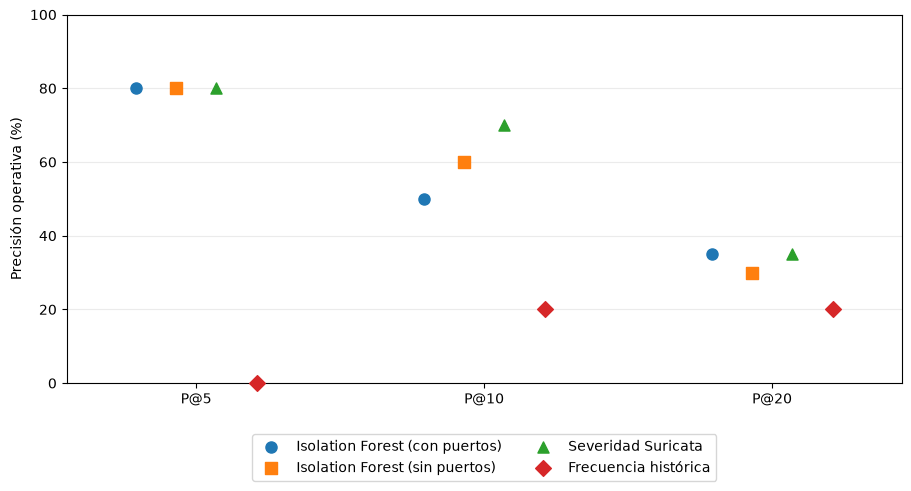

Archivos generados en: /home/nemsis/tfm/anexo_h
  H1_if_con_puertos.csv
  H2_if_sin_puertos.csv
  H3_severidad.csv
  H4_frecuencia.csv
  H5_etiquetado_final.csv
  H6_if_filtrado.csv
  H_precision_por_corte.png


In [27]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

# 1. Cargar el consenso definitivo y el mapeo del paquete de revisión.
ruta_consenso = Path.home() / "tfm" / "consenso" / "consenso_final_64.csv"
ruta_mapeo = directorio_revision / "mapeo_privado_metodos.csv"
salida_anexo = Path.home() / "tfm" / "anexo_h"

columnas_consenso = ["id_revision", "veracidad_final", "prioridad_final"]
consenso = pd.read_csv(
    ruta_consenso, encoding="utf-8-sig", dtype="string", usecols=columnas_consenso
)
for columna in columnas_consenso:
    consenso[columna] = consenso[columna].str.strip()
for columna in ["veracidad_final", "prioridad_final"]:
    consenso[columna] = consenso[columna].str.lower()

mapeo = pd.read_csv(
    ruta_mapeo, encoding="utf-8-sig", dtype={"id_revision": "string"}
)
mapeo["id_revision"] = mapeo["id_revision"].str.strip()

if (
    len(consenso) != 64
    or consenso[columnas_consenso].fillna("").eq("").any().any()
    or consenso["id_revision"].duplicated().any()
    or set(consenso["id_revision"]) != set(mapeo["id_revision"])
):
    raise ValueError("El consenso debe cubrir los 64 identificadores del mapeo.")

recuento_final = consenso.groupby(
    ["veracidad_final", "prioridad_final"]
).size()
if recuento_final.to_dict() != {
    ("verdadero positivo", "alta"): 1,
    ("verdadero positivo", "media"): 17,
    ("falso positivo", "baja"): 46,
}:
    raise ValueError("El etiquetado final difiere del apartado 5.5.1.")

archivos = {
    "Isolation Forest (con puertos)": "H1_if_con_puertos.csv",
    "Isolation Forest (sin puertos)": "H2_if_sin_puertos.csv",
    "Severidad Suricata": "H3_severidad.csv",
    "Frecuencia histórica": "H4_frecuencia.csv",
}

if len(mapeo) != 80 or set(mapeo["metodo"]) != set(archivos):
    raise ValueError("El mapeo debe contener 80 posiciones de los cuatro rankings.")

for metodo in archivos:
    filas = mapeo.loc[mapeo["metodo"].eq(metodo)].sort_values("posicion")
    if (
        filas["posicion"].tolist() != list(range(1, 21))
        or filas["indice_alerta"].tolist() != rankings[metodo].head(20).index.tolist()
    ):
        raise ValueError(f"El mapeo no coincide con el ranking actual de {metodo}.")

identidades = mapeo[["indice_alerta", "id_revision"]].drop_duplicates()
if identidades["indice_alerta"].duplicated().any() or identidades["id_revision"].duplicated().any():
    raise ValueError("Cada alerta debe tener un único identificador de revisión.")

# 2. Preparar los rankings principales y el top 20 filtrado.
principal = mapeo.merge(consenso, on="id_revision", validate="many_to_one")
principal["relevante"] = (
    principal["veracidad_final"].eq("verdadero positivo")
    & principal["prioridad_final"].isin(["alta", "media"])
).astype(int)

filtrado = pd.DataFrame({
    "posicion": range(1, 21),
    "indice_alerta": top20_if_sens.index,
})

indices = pd.Index(pd.concat(
    [principal["indice_alerta"], filtrado["indice_alerta"]],
    ignore_index=True,
).drop_duplicates())

contexto = df_alertas.loc[indices, ["alert.signature_id", "flow_id"]].copy()
contexto["alerta"] = [f"A{numero:03d}" for numero in range(1, len(contexto) + 1)]

# Reutilizo los códigos para poder seguir la misma alerta entre tablas.
for original, columna, prefijo in [
    ("alert.signature_id", "firma", "S"),
    ("flow_id", "flujo", "F"),
]:
    codigos = {
        valor: f"{prefijo}{numero:03d}"
        for numero, valor in enumerate(contexto[original].dropna().unique(), start=1)
    }
    contexto[columna] = contexto[original].map(codigos).fillna("—")

columnas_contexto = ["alerta", "firma", "flujo"]
principal = principal.join(contexto[columnas_contexto], on="indice_alerta")
filtrado = filtrado.join(contexto[columnas_contexto], on="indice_alerta")

filtrado["revision"] = filtrado["indice_alerta"].isin(
    identidades["indice_alerta"]
).map({True: "Revisada", False: "Sin revisar"})

indices_originales = rankings["Isolation Forest (con puertos)"].head(20).index
filtrado["en_top20_original"] = filtrado["indice_alerta"].isin(
    indices_originales
).map({True: "Sí", False: "No"})

if (
    filtrado["revision"].eq("Revisada").sum() != 8
    or filtrado["en_top20_original"].eq("Sí").sum() != 6
):
    raise ValueError("La cobertura del ranking filtrado difiere del apartado 5.6.")

# 3. Preparar las tablas y comprobar la precisión y la diversidad del capítulo 5.
cortes = [5, 10, 20]
tablas = {}
filas_resumen = []

for metodo, nombre_archivo in archivos.items():
    top = principal.loc[principal["metodo"].eq(metodo)].sort_values("posicion")
    tablas[nombre_archivo] = top[[
        "posicion", "alerta", "firma", "flujo",
        "veracidad_final", "prioridad_final", "relevante",
    ]]

    filas_resumen.append({
        "metodo": metodo,
        **{f"P@{k}": int(top.head(k)["relevante"].sum()) for k in cortes},
        "firmas_distintas": top.loc[top["firma"].ne("—"), "firma"].nunique(),
        "flujos_distintos": top.loc[top["flujo"].ne("—"), "flujo"].nunique(),
        "alertas_sin_flujo": int(top["flujo"].eq("—").sum()),
    })

resumen = pd.DataFrame(filas_resumen).set_index("metodo")
esperado = [
    [4, 5, 7, 4, 14, 0],
    [4, 6, 6, 4, 9, 0],
    [4, 7, 7, 7, 11, 1],
    [0, 2, 4, 13, 16, 0],
]
if resumen.to_numpy().tolist() != esperado:
    display(resumen)
    raise ValueError("Los recuentos no coinciden con las tablas 9 y 10 del capítulo 5.")

tablas["H5_etiquetado_final.csv"] = (
    recuento_final.rename("alertas").reset_index()
)
tablas["H6_if_filtrado.csv"] = filtrado[[
    "posicion", "alerta", "firma", "flujo", "en_top20_original", "revision",
]]

# 4. Exportar las tablas. Se guardan únicamente las columnas del anexo.
salida_anexo.mkdir(parents=True, exist_ok=True)
for nombre_archivo, tabla in tablas.items():
    tabla.to_csv(
        salida_anexo / nombre_archivo,
        sep=";", encoding="utf-8-sig", index=False,
    )

# 5. Generar la Figura H.1 con marcadores separados para visualizar los empates.
fig, ax = plt.subplots(figsize=(9, 4.8), layout="constrained")
marcadores = ["o", "s", "^", "D"]
desplazamientos = [-0.21, -0.07, 0.07, 0.21]

for (metodo, fila), marcador, desplazamiento in zip(
    resumen.iterrows(), marcadores, desplazamientos
):
    ax.scatter(
        [posicion + desplazamiento for posicion in range(len(cortes))],
        [100 * fila[f"P@{k}"] / k for k in cortes],
        marker=marcador, s=64, label=metodo, clip_on=False, zorder=3,
    )

ax.set_xticks(range(len(cortes)), [f"P@{k}" for k in cortes])
ax.set_xlim(-0.45, 2.45)
ax.set_ylim(0, 100)
ax.set_ylabel("Precisión operativa (%)")
ax.grid(axis="y", alpha=0.25)
ax.set_axisbelow(True)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=2)

nombre_figura = "H_precision_por_corte.png"
fig.savefig(salida_anexo / nombre_figura, dpi=300, bbox_inches="tight")
plt.show()

print(f"Archivos generados en: {salida_anexo}")
for nombre_archivo in [*tablas, nombre_figura]:
    print(f"  {nombre_archivo}")